# Wegen, ongevalstypen en lokale hotspots

## Doel en interpretatie
Deze analyse zoekt **kandidaatlocaties voor onderzoek**. We koppelen gegeocodeerde ongevalspunten bij benadering aan de dichtstbijzijnde OpenStreetMap-weg binnen 30 meter. Een ongeval op een kruispunt kan daardoor aan de verkeerde weg worden toegeschreven. Straatranglijsten gelden voor de gegeocodeerde ongevallen in 2024 en missen ongevallen zonder coördinaten. Absolute aantallen en letselklassen meten geen gevaar per bestuurder zonder verkeersintensiteit. Clusters geven hypotheses; geen bewezen oorzaak.

De drie GetYouStarted-notebooks inspireerden de stapsgewijze opbouw en kaartlagen. Dit notebook gebruikt de verkeersdata en de gecachte OSM-wegen uit het eigen project.

In [1]:
from pathlib import Path
import pandas as pd,numpy as np,geopandas as gpd,matplotlib.pyplot as plt
from scipy.stats import binomtest
from IPython.display import display
B=Path.cwd()
if not (B/'figures').exists():B=B/'analysis_notebooks'
T=B/'tables';F=B/'figures';G=B.parent/'data/gold'
d=pd.read_parquet(G/'accident_map/accident_map.parquet')
roads=gpd.read_parquet(B/'reference_data/roads_belgium.parquet')
country=gpd.read_file(B/'reference_data/belgium_2024.geojson').to_crs(31370)
palette=['#175A78','#D76B32','#9B654D']
def save(fig,name):
 fig.tight_layout();fig.savefig(F/(name+'.png'),dpi=200,bbox_inches='tight');fig.savefig(F/(name+'.svg'),bbox_inches='tight');plt.show();plt.close(fig)


## 1. Controle van de analysepopulatie
We gebruiken de eerder opgeslagen geografische kwaliteitsselectie. Onbekende wegen en ongeldige coördinaten blijven in de volledige bron, maar vallen buiten de ruimtelijke ranglijsten.

In [2]:

bad=set(pd.read_csv(T/'geo_uitgesloten.csv',usecols=['_record_id'])._record_id)
source=d[(d.analysis_year==2024)&~d._record_id.isin(bad)].copy()
points=gpd.GeoDataFrame(source,geometry=gpd.points_from_xy(source.MS_X_COORD,source.MS_Y_COORD),crs=31370)
assert len(points)==33830
print('2024 kaartregistraties:',len(d[d.analysis_year==2024]),'bruikbaar:',len(points))
display(points.CD_ROAD_TYPE_NL.value_counts().to_frame('registraties'))


2024 kaartregistraties: 35916 bruikbaar: 33830


,registraties
CD_ROAD_TYPE_NL,
Gemeenteweg,15921
Gewestweg,15457
Autosnelweg,2438
onbekend,14


## 2. Benoemde wegen: kandidaat-ranglijst
Een naam kan meerdere OSM-segmenten hebben. We groeperen op **gemeente + wegnaam + OSM-klasse**, tellen het aantal unieke kaartregistraties en bewaren de afstand tot het gematchte segment. Onbenoemde wegen krijgen geen geforceerde naam.

Binnen 30 m van rijweg: 33496 benoemd: 32247 zonder toewijzing: 334


,TX_MUNTY_COLLISION_NL,wegnaam,CD_ROAD_TYPE_NL,registraties,ernstige_klasse,mediane_afstand_m,ernstaand_pct
1229,Antwerpen,R1,Autosnelweg,122,5,0.7,4.1
760,Antwerpen,Boomsesteenweg,Gewestweg,67,1,0.4,1.5
508,Anderlecht,Chaussée de Mons - Bergense Steenweg,Gewestweg,56,1,0.4,1.8
773,Antwerpen,Bredabaan,Gewestweg,54,5,0.4,9.3
748,Antwerpen,Bisschoppenhoflaan,Gewestweg,47,3,0.4,6.4
2622,Brasschaat,Bredabaan,Gewestweg,39,1,0.3,2.6
11451,Oostende,Torhoutsesteenweg,Gewestweg,37,5,1.8,13.5
13177,Sint-Jans-Molenbeek,Chaussée de Gand - Steenweg op Gent,Gewestweg,37,2,0.4,5.4
1171,Antwerpen,Noorderlaan,Gewestweg,37,1,0.6,2.7
1173,Antwerpen,Noordersingel,Gewestweg,37,0,0.8,0.0


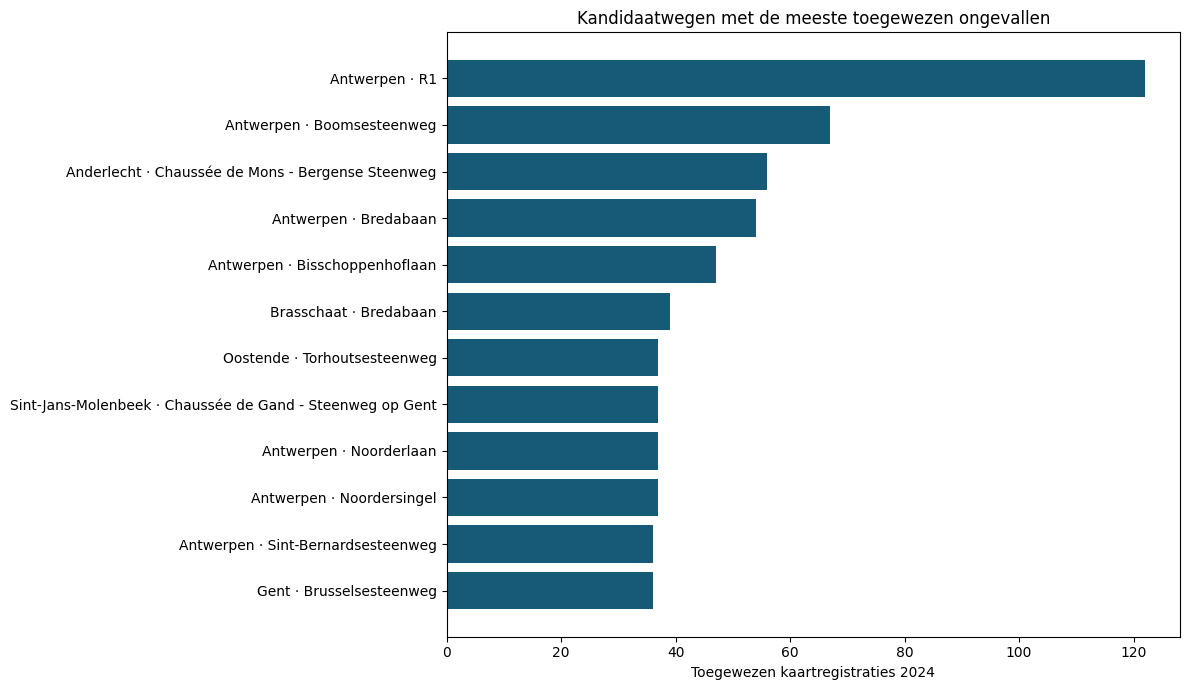

In [3]:

drivable=['motorway','motorway_link','trunk','trunk_link','primary','primary_link','secondary','secondary_link','tertiary','tertiary_link','residential','unclassified','living_street','service']
network=roads[roads.fclass.isin(drivable)][['osm_id','fclass','name','ref','geometry']].copy()
network=network[network.geometry.notna()]
match=gpd.sjoin_nearest(points[['geometry','_record_id','TX_MUNTY_COLLISION_NL','CD_ROAD_TYPE_NL','TX_COLLISION_TYPE_NL','TX_CLASS_ACCIDENTS_NL']],network,how='left',max_distance=30,distance_col='afstand_m')
match=match.sort_values(['_record_id','afstand_m','osm_id']).drop_duplicates('_record_id')
assert len(match)==len(points)
match['wegnaam']=match['name'].fillna(match['ref'])
match['ernstig']=match.TX_CLASS_ACCIDENTS_NL.isin(['met zwaargewonden','met doden','met dodelijk gewonden'])
matched=match[match.wegnaam.notna()].copy()
ranking=matched.groupby(['TX_MUNTY_COLLISION_NL','wegnaam','CD_ROAD_TYPE_NL'],dropna=False).agg(registraties=('_record_id','nunique'),ernstige_klasse=('ernstig','sum'),mediane_afstand_m=('afstand_m','median')).reset_index()
ranking=ranking[ranking.registraties>=5].sort_values(['registraties','ernstige_klasse'],ascending=False)
ranking['ernstaand_pct']=100*ranking.ernstige_klasse/ranking.registraties
ranking.to_csv(T/'kandidaat_wegen_2024.csv',index=False)
matched.drop(columns='geometry').to_csv(T/'wegmatch_2024.csv',index=False)
print('Binnen 30 m van rijweg:',match.osm_id.notna().sum(),'benoemd:',len(matched),'zonder toewijzing:',match.osm_id.isna().sum())
display(ranking.head(20).round(1))
fig,ax=plt.subplots(figsize=(12,7));top=ranking.head(12).iloc[::-1];ax.barh(top.TX_MUNTY_COLLISION_NL+' · '+top.wegnaam,top.registraties,color=palette[0]);ax.set(xlabel='Toegewezen kaartregistraties 2024',title='Kandidaatwegen met de meeste toegewezen ongevallen');save(fig,'15_kandidaat_wegen')


## 3. Ernst per wegtype
Vergelijk op basis van de **klasse van het ongeval in dezelfde kaartbron**. Een hoog percentage geeft het aandeel ernstige klassen onder reeds geregistreerde ongevallen, geen kans per gereden kilometer.

,registraties,ernstig,ernstaand_pct
CD_ROAD_TYPE_NL,,,
Autosnelweg,2438,179,7.34
Gemeenteweg,15921,1276,8.01
Gewestweg,15457,1135,7.34
onbekend,14,1,7.14


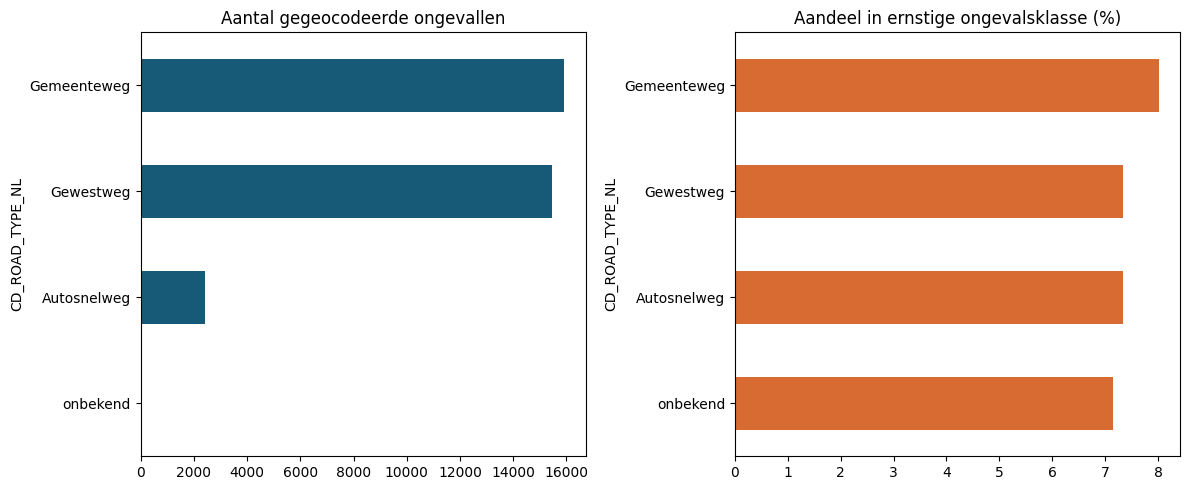

In [4]:

bytype=points.groupby('CD_ROAD_TYPE_NL').agg(registraties=('_record_id','nunique'),ernstig=('TX_CLASS_ACCIDENTS_NL',lambda s:s.isin(['met zwaargewonden','met doden','met dodelijk gewonden']).sum()))
bytype['ernstaand_pct']=100*bytype.ernstig/bytype.registraties
bytype.to_csv(T/'wegtype_ernstige_ongevallen_kaart_2024.csv');display(bytype.round(2))
fig,axes=plt.subplots(1,2,figsize=(12,5))
bytype.registraties.sort_values().plot.barh(ax=axes[0],color=palette[0],title='Aantal gegeocodeerde ongevallen')
bytype.ernstaand_pct.sort_values().plot.barh(ax=axes[1],color=palette[1],title='Aandeel in ernstige ongevalsklasse (%)')
save(fig,'16_wegtype_volume_en_ernst')


## 4. Waar komt een ongevalstype opvallend vaak voor?
We gebruiken vaste cellen van 500 × 500 meter. Alleen cellen met minstens 20 registraties worden getest. De lokale typeverdeling vergelijken we met hetzelfde wegtype in heel België. Een exacte binomiale toets vindt ongebruikelijke samenstellingen; Benjamini–Hochberg corrigeert voor veel vergelijkingen. Dit is een signalering voor veldonderzoek, geen causale test.

In [5]:

CELL=500
points['gx']=(points.geometry.x//CELL).astype(int);points['gy']=(points.geometry.y//CELL).astype(int)
local=points.groupby(['gx','gy','CD_ROAD_TYPE_NL','TX_COLLISION_TYPE_NL']).size().rename('k').reset_index()
denom=points.groupby(['gx','gy','CD_ROAD_TYPE_NL']).size().rename('n').reset_index()
local=local.merge(denom,on=['gx','gy','CD_ROAD_TYPE_NL'],validate='many_to_one')
baseline=points.groupby(['CD_ROAD_TYPE_NL','TX_COLLISION_TYPE_NL']).size().rename('base_k').reset_index()
base_n=points.groupby('CD_ROAD_TYPE_NL').size().rename('base_n').reset_index()
baseline=baseline.merge(base_n,on='CD_ROAD_TYPE_NL');baseline['base_pct']=baseline.base_k/baseline.base_n
local=local.merge(baseline[['CD_ROAD_TYPE_NL','TX_COLLISION_TYPE_NL','base_pct']],on=['CD_ROAD_TYPE_NL','TX_COLLISION_TYPE_NL'])
signals=local[(local.n>=20)&(local.base_pct>0)].copy()
signals['p']=signals.apply(lambda r:binomtest(int(r.k),int(r.n),float(r.base_pct),alternative='greater').pvalue,axis=1)
signals=signals.sort_values('p').reset_index(drop=True)
if len(signals):
 signals['q']=np.minimum.accumulate((signals.p.to_numpy()*len(signals)/(np.arange(len(signals))+1))[::-1])[::-1].clip(max=1)
signals['local_pct']=100*signals.k/signals.n;signals['base_pct']=100*signals.base_pct
signals['x_m']=(signals.gx+.5)*CELL;signals['y_m']=(signals.gy+.5)*CELL
signals=signals[(signals.k>=8)&(signals.local_pct>=signals.base_pct*1.5)&(signals.q<.05)].sort_values(['q','k']);signals.to_csv(T/'botsingstype_clusters_2024.csv',index=False)
display(signals.head(20).round(3))


,gx,gy,CD_ROAD_TYPE_NL,TX_COLLISION_TYPE_NL,k,n,base_pct,p,q,local_pct,x_m,y_m
0,300,337,Gemeenteweg,Met een voetganger,10,23,12.600,0.000,0.035,43.478,150250.0,168750.0
1,212,388,Gewestweg,Tss. 2 best.: langs opzij (voor-/achterkant-fl...,16,24,32.607,0.001,0.047,66.667,106250.0,194250.0


## 5. Bekijk de locatie, niet alleen de score
De kaart toont de grootste 500-m-cellen met een ongebruikelijke typeverdeling. Raadpleeg voor een casus ook de bronregels: kruispunt, licht, weer en ernst. Een mogelijk mechanisme blijft een hypothese totdat de wegbeheerder infrastructuur, verkeersstromen en politiegegevens controleert.

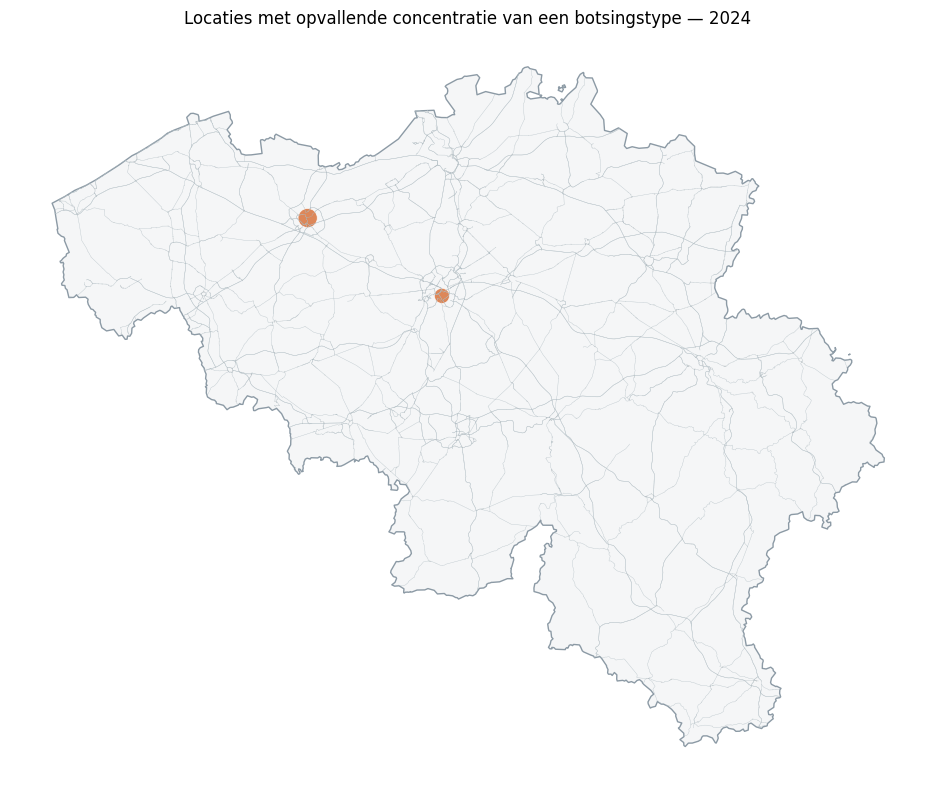


 TX_MUNTY_COLLISION_NL


,aantal
TX_MUNTY_COLLISION_NL,
Elsene,23



 TX_COLLISION_TYPE_NL


,aantal
TX_COLLISION_TYPE_NL,
Met een voetganger,10
Tss. 2 best.: langs opzij (voor-/achterkant-flank),4
Tussen 2 bestuurders: Langs achteren,3
Tussen 2 bestuurders: Flank tegen flank,2
"Eén bestuurder, geen hindernis (incl. val)",2
Tussen 2 bestuurders: Frontale botsing,2



 TX_CROSSWAY_NL


,aantal
TX_CROSSWAY_NL,
Buiten Kruispunt,19
Op Kruispunt,4


... (2 outputs left out)


 TX_WEATHER_NL


,aantal
TX_WEATHER_NL,
Normaal,15
Onbekend,4
Regenval,4



 TX_CLASS_ACCIDENTS_NL


,aantal
TX_CLASS_ACCIDENTS_NL,
met lichtgewonden,23


In [6]:

if len(signals):
 top=signals[signals.q<.05].head(15).copy()
 fig,ax=plt.subplots(figsize=(11,8));country.plot(ax=ax,color='#F5F6F7',edgecolor='#8C9AA5');roadlines=roads[roads.fclass.isin(['motorway','trunk','primary'])];roadlines.plot(ax=ax,color='#B5C1C7',linewidth=.25)
 ax.scatter(top.x_m,top.y_m,s=top.k*12,c='#D76B32',edgecolors='white',linewidths=.6,alpha=.8)
 ax.axis('off');ax.set_title('Locaties met opvallende concentratie van een botsingstype — 2024');save(fig,'17_botsingstype_clusters')
 if len(top):
  r=top.iloc[0];sample=points[(points.gx==r.gx)&(points.gy==r.gy)&(points.CD_ROAD_TYPE_NL==r.CD_ROAD_TYPE_NL)]
  cols=['TX_MUNTY_COLLISION_NL','TX_COLLISION_TYPE_NL','TX_CROSSWAY_NL','TX_LIGHT_CONDITION_NL','TX_WEATHER_NL','TX_CLASS_ACCIDENTS_NL']
  for col in cols:print('\n',col);display(sample[col].value_counts(dropna=False).head(8).to_frame('aantal'))
  sample.drop(columns='geometry').to_csv(T/'voorbeeld_cluster_bronregels.csv',index=False)


## Handover en vervolg
Een benoemde weg in de ranglijst is een **onderzoekskandidaat**. Controleer wegidentiteit en kruispunten op een kaart voordat de naam in een presentatie als feitelijke ongevalsweg verschijnt. Gebruik de typeclusters om gerichte hypotheses te formuleren, bijvoorbeeld zicht, afslaand verkeer of snelheid, en toets die met verkeersintensiteit, wegontwerp en detailregistraties. De huidige data leveren geen bewijs van de oorzaak.

Bronnen: lokale Statbel kaartgegevens 2017–2024; OSM/Geofabrik wegen 01-01-2025; GISCO-grens 2024. Ongeveer 5,8% van de kaartregistraties van 2024 mist coördinaten en is niet in de ruimtelijke ranglijsten opgenomen.